# Historical binary experiment
Preserved for reference. Active 10-class experiments and run commands are in `README.md` and `docs/TECHNIQUES_AND_RUNS.md`. These notebook outputs use binary `label` and must not be compared directly with multiclass results.

# 01. TIỀN XỬ LÝ & PHÂN TÍCH TOÀN DIỆN UNSW-NB15 (CENTRALIZED & FEDERATED)

Mục tiêu của quy trình tích hợp:
1. **Khám phá & Chẩn đoán dữ liệu (EDA)**: Phân tích độ lệch (Skewness), trực quan hóa phân phối, phát hiện ngoại lai (Boxplot), và kiểm tra tương quan/đa cộng tuyến (Pearson Correlation).
2. **Tiền xử lý chuẩn mực & Không rò rỉ dữ liệu (Strictly Leak-Free)**: Thống kê chuẩn hóa (Mean, Std) và từ vựng One-Hot chỉ được khớp (fit) trên tập Train, sau đó ánh xạ (transform) sang tập Test.
3. **Tương thích hoàn hảo giữa Centralized và Federated Learning**:
   - Client tính toán thống kê cục bộ `(n, mean, M2)` trên `log1p(cột số)` và tập category, bảo vệ quyền riêng tư dữ liệu thô.
   - Server gộp thống kê bằng **thuật toán Chan** (Chan's algorithm for parallel variance update) với sai số so với tính tập trung xấp xỉ $10^{-15}$ (bằng đúng epsilon dấu phẩy động của máy tính).
   - Xử lý triệt để danh mục mới chưa từng thấy (unseen categories) bằng vector 0, giữ cố định đúng 191 đặc trưng.
4. **Đóng gói sản phẩm**: Xuất file `output_preprocess/preprocess.joblib` và `output_preprocess/data.npz` làm đầu vào chuẩn cho `02_centralized_baseline.ipynb` và các kịch bản huấn luyện phân tán trong `distributed_training/`.

---
### Bảng so sánh phương pháp tiền xử lý
| Thành phần | Tiền xử lý tập trung thông thường | Pipeline tối ưu trong Notebook này |
|---|---|---|
| **Chuẩn hóa** | `StandardScaler` fit trên toàn bộ train gộp lại | Mỗi client gửi `(n, mean, M2)`, server gộp bằng công thức Chan (kết quả chuẩn xác tuyệt đối) |
| **Giảm lệch** | Bỏ qua hoặc dùng các phép biến đổi phức tạp | Dùng `log1p(x)`: công thức đóng $x \mapsto \ln(1+x)$, triệt tiêu lệch phải, tính toán cục bộ dễ dàng |
| **One-Hot** | `get_dummies` trên tập gộp, dễ lệch cột | Mỗi client gửi tập category, server lấy hợp rồi phát lại; category mới được mã hóa toàn 0 |
| **PCA** | Ép chiều dữ liệu làm mất thông tin | Chỉ dùng phân tích trực quan EDA; không đưa vào pipeline chính để giữ độ chính xác tối đa cho Tree Models |


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.decomposition import PCA

try:
    from IPython.display import display
except ImportError:
    display = print

# Cấu hình giao diện vẽ đồ thị
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.unicode_minus'] = False

# Tự động định vị đường dẫn dữ liệu
def resolve_data_paths():
    search_dirs = [
        '.',
        os.path.join('CSV Files', 'Training and Testing Sets'),
        'CSV Files',
        '..'
    ]
    train_file = 'UNSW_NB15_training-set.csv'
    test_file = 'UNSW_NB15_testing-set.csv'
    train_path, test_path = None, None
    for d in search_dirs:
        p_train = os.path.join(d, train_file)
        p_test = os.path.join(d, test_file)
        if os.path.exists(p_train) and train_path is None:
            train_path = p_train
        if os.path.exists(p_test) and test_path is None:
            test_path = p_test
    return train_path or train_file, test_path or test_file

TRAIN_PATH, TEST_PATH = resolve_data_paths()
OUT_DIR = 'output_preprocess'
os.makedirs(OUT_DIR, exist_ok=True)

CAT_COLS = ['proto', 'service', 'state']
DROP_COLS = ['id', 'attack_cat']
N_CLIENTS = 5          # Mô phỏng việc gộp thống kê theo kiến trúc federated
SPLIT_SEED = 0

print(f'Train path: {TRAIN_PATH}')
print(f'Test path : {TEST_PATH}')
print(f'Output dir: {OUT_DIR}')


Train path: ./UNSW_NB15_training-set.csv
Test path : ./UNSW_NB15_testing-set.csv
Output dir: output_preprocess


## Phần 1: Nạp dữ liệu, Làm sạch & Kiểm tra sơ bộ

- Điền giá trị khuyết thiếu bằng kỹ thuật đệm tiến kết hợp đệm lùi (`ffill().bfill()`).
- Loại bỏ các cột định danh hoặc nhãn phụ không cần cho phân loại nhị phân (`id`, `attack_cat`).
- Đồng bộ tên cột `ackdat` thành `ackdata` (chuẩn hóa quy ước danh pháp của UNSW-NB15).


In [2]:
def clean(df):
    """Điền thiếu, bỏ id/attack_cat, đổi ackdat -> ackdata. Giữ cột label nếu có."""
    df = df.ffill().bfill()
    return df.drop(columns=DROP_COLS, errors='ignore').rename(columns={'ackdat': 'ackdata'})

raw = pd.read_csv(TRAIN_PATH, encoding='utf-8-sig')
test_raw = pd.read_csv(TEST_PATH, encoding='utf-8-sig')

print('Train thô:', raw.shape, '| Test thô:', test_raw.shape)
print('Giá trị thiếu: train', int(raw.isnull().sum().sum()), '| test', int(test_raw.isnull().sum().sum()))

train = clean(raw)
NUM_COLS = [c for c in train.select_dtypes(include=[np.number]).columns if c != 'label']
print(f'Số lượng cột số: {len(NUM_COLS)} | Cột phân loại: {CAT_COLS}')
print('Tỷ lệ nhãn tấn công (Attack=1):')
print('  - Tập Train: {:.2%}'.format(raw['label'].mean()))
print('  - Tập Test : {:.2%}'.format(test_raw['label'].mean()))


Train thô: (175341, 45) | Test thô: (82332, 45)
Giá trị thiếu: train 0 | test 0
Số lượng cột số: 39 | Cột phân loại: ['proto', 'service', 'state']
Tỷ lệ nhãn tấn công (Attack=1):
  - Tập Train: 68.06%
  - Tập Test : 55.06%


## Phần 2: Khám phá Dữ liệu & Trực quan hóa Chẩn đoán (EDA & Diagnostics)

Để hiểu rõ đặc tính vật lý của lưu lượng mạng trong tập UNSW-NB15, ta tiến hành phân tích sâu 13 đặc trưng lưu lượng cốt lõi:
1. `sbytes`, `dbytes`: Số byte gửi từ nguồn và đích.
2. `sload`, `dload`: Băng thông truyền dữ liệu (bit/giây).
3. `dur`: Tổng thời gian kết nối (giây).
4. `rate`: Tốc độ truyền gói tin trên giây (pps).
5. `sinpkt`, `dinpkt`: Khoảng cách thời gian giữa các gói tin nguồn và đích.
6. `sjit`, `djit`: Độ giật trễ (jitter) nguồn và đích (ms).
7. `tcprtt`, `synack`, `ackdata`: Thời gian trễ trong quá trình bắt tay 3 bước của giao thức TCP.


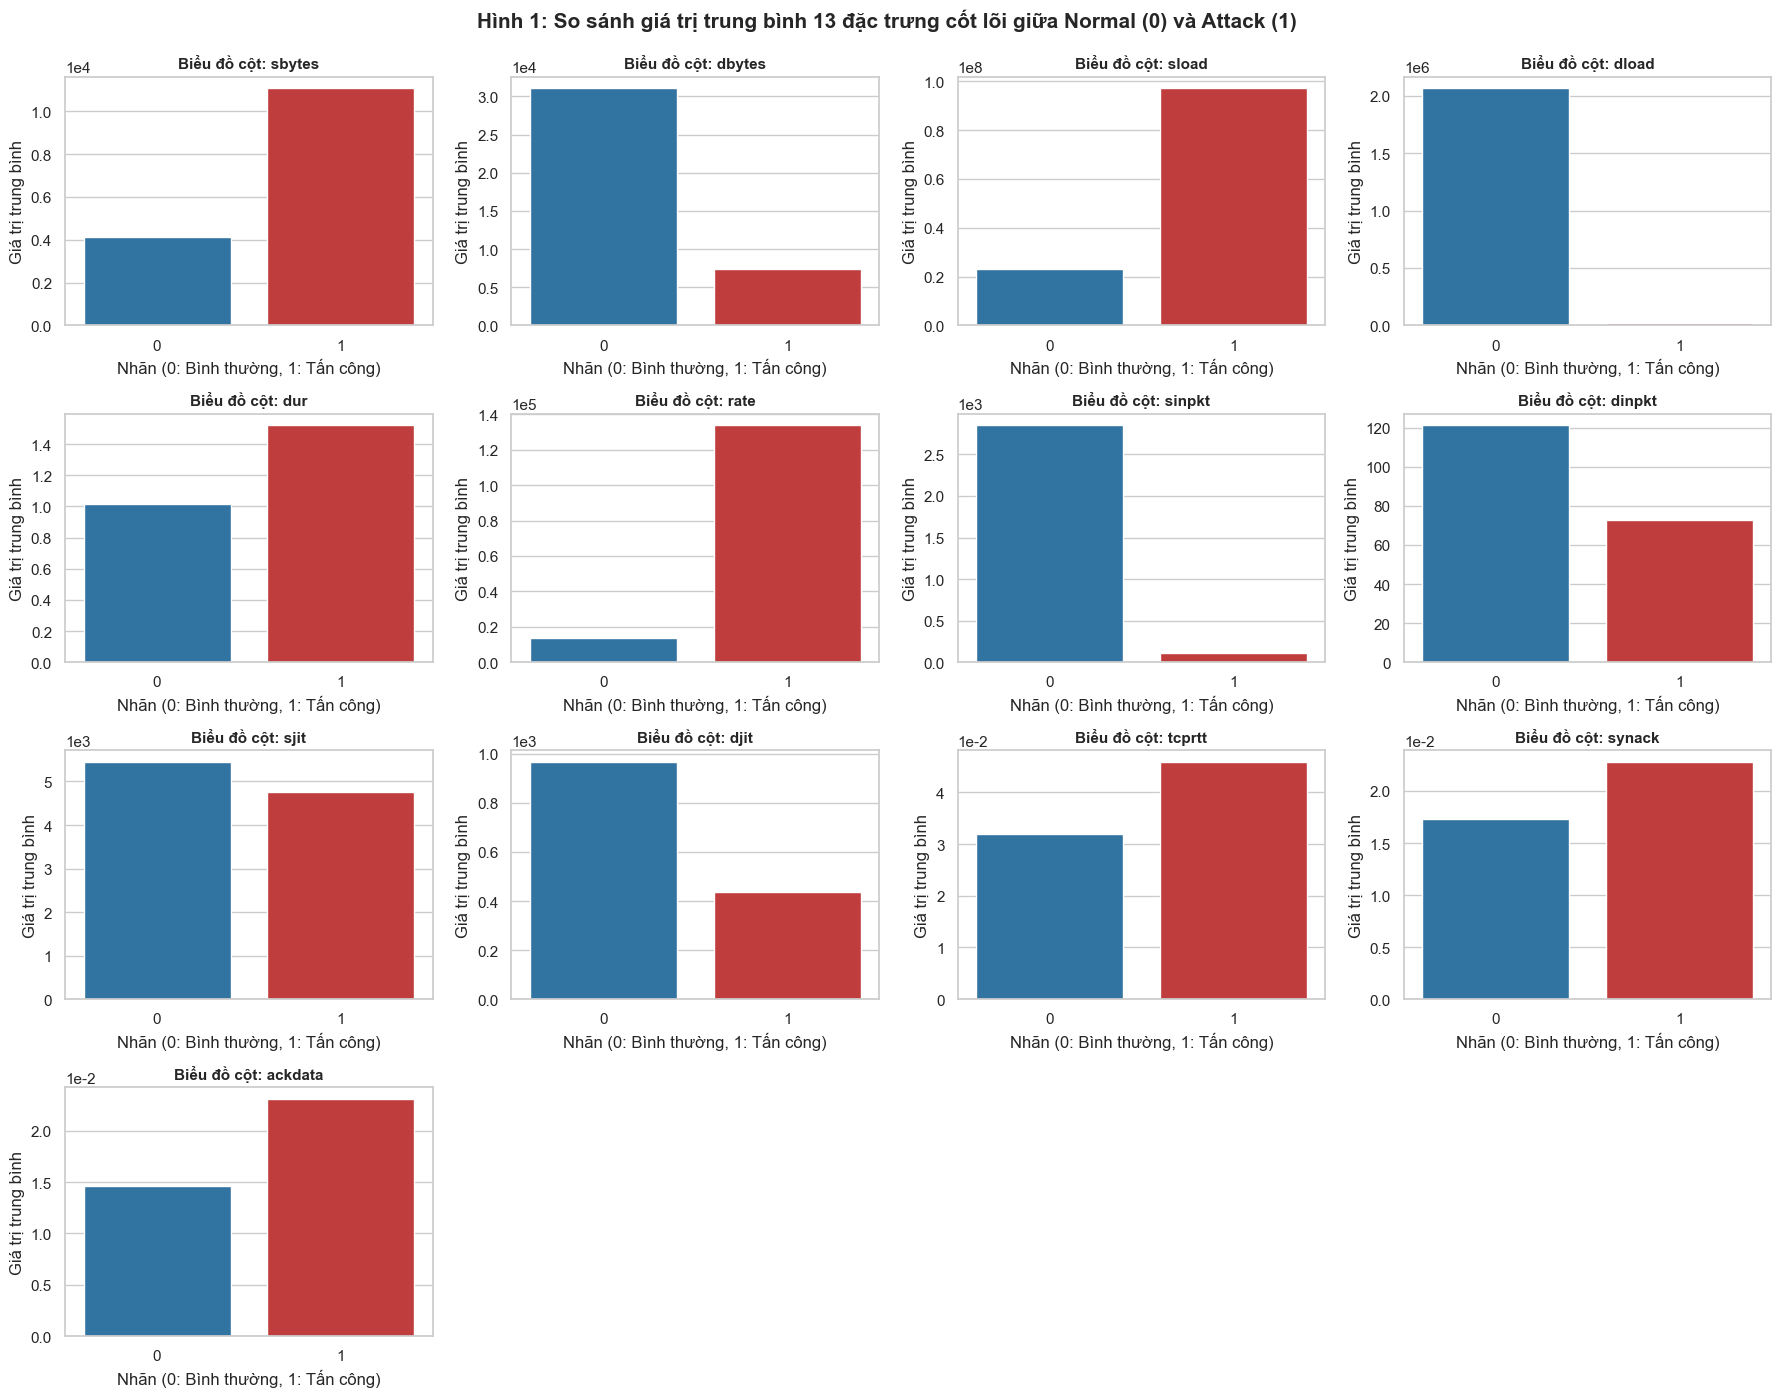

In [3]:
target_features = [
    'sbytes', 'dbytes', 'sload', 'dload', 'dur', 'rate',
    'sinpkt', 'dinpkt', 'sjit', 'djit', 'tcprtt', 'synack', 'ackdata'
]

# 2.1 Biểu đồ cột: So sánh giá trị trung bình giữa Bình thường (0) và Tấn công (1)
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(target_features):
    grouped = train.groupby('label')[col].mean().reset_index()
    sns.barplot(
        data=grouped, x='label', y=col, ax=axes[i],
        hue='label', palette=['#1f77b4', '#d62728'], legend=False
    )
    axes[i].set_title(f'Biểu đồ cột: {col}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Nhãn (0: Bình thường, 1: Tấn công)')
    axes[i].set_ylabel('Giá trị trung bình')
    axes[i].ticklabel_format(style='sci', scilimits=(-2, 3), axis='y')

for j in range(len(target_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Hình 1: So sánh giá trị trung bình 13 đặc trưng cốt lõi giữa Normal (0) và Attack (1)', fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


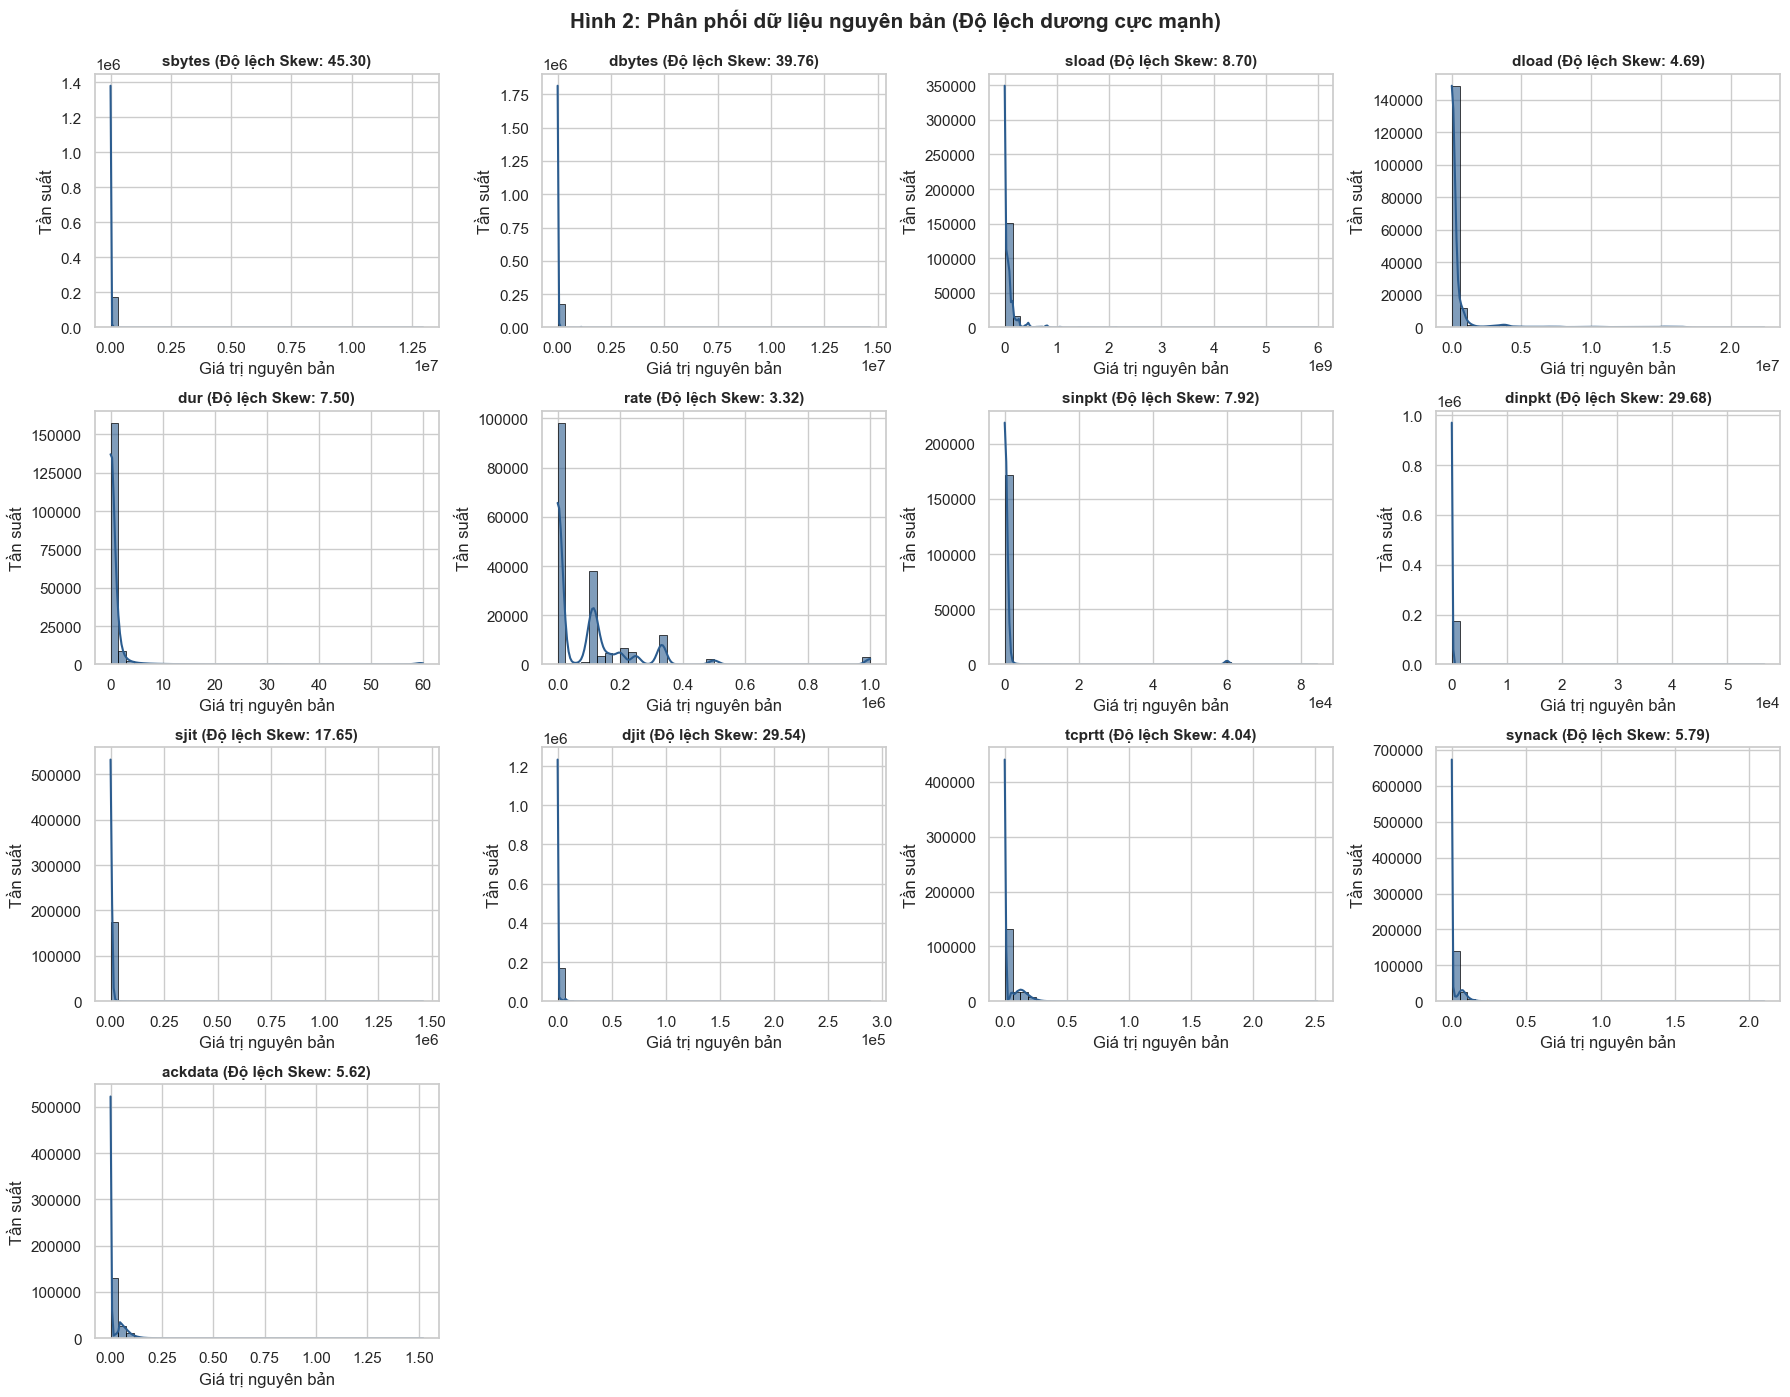

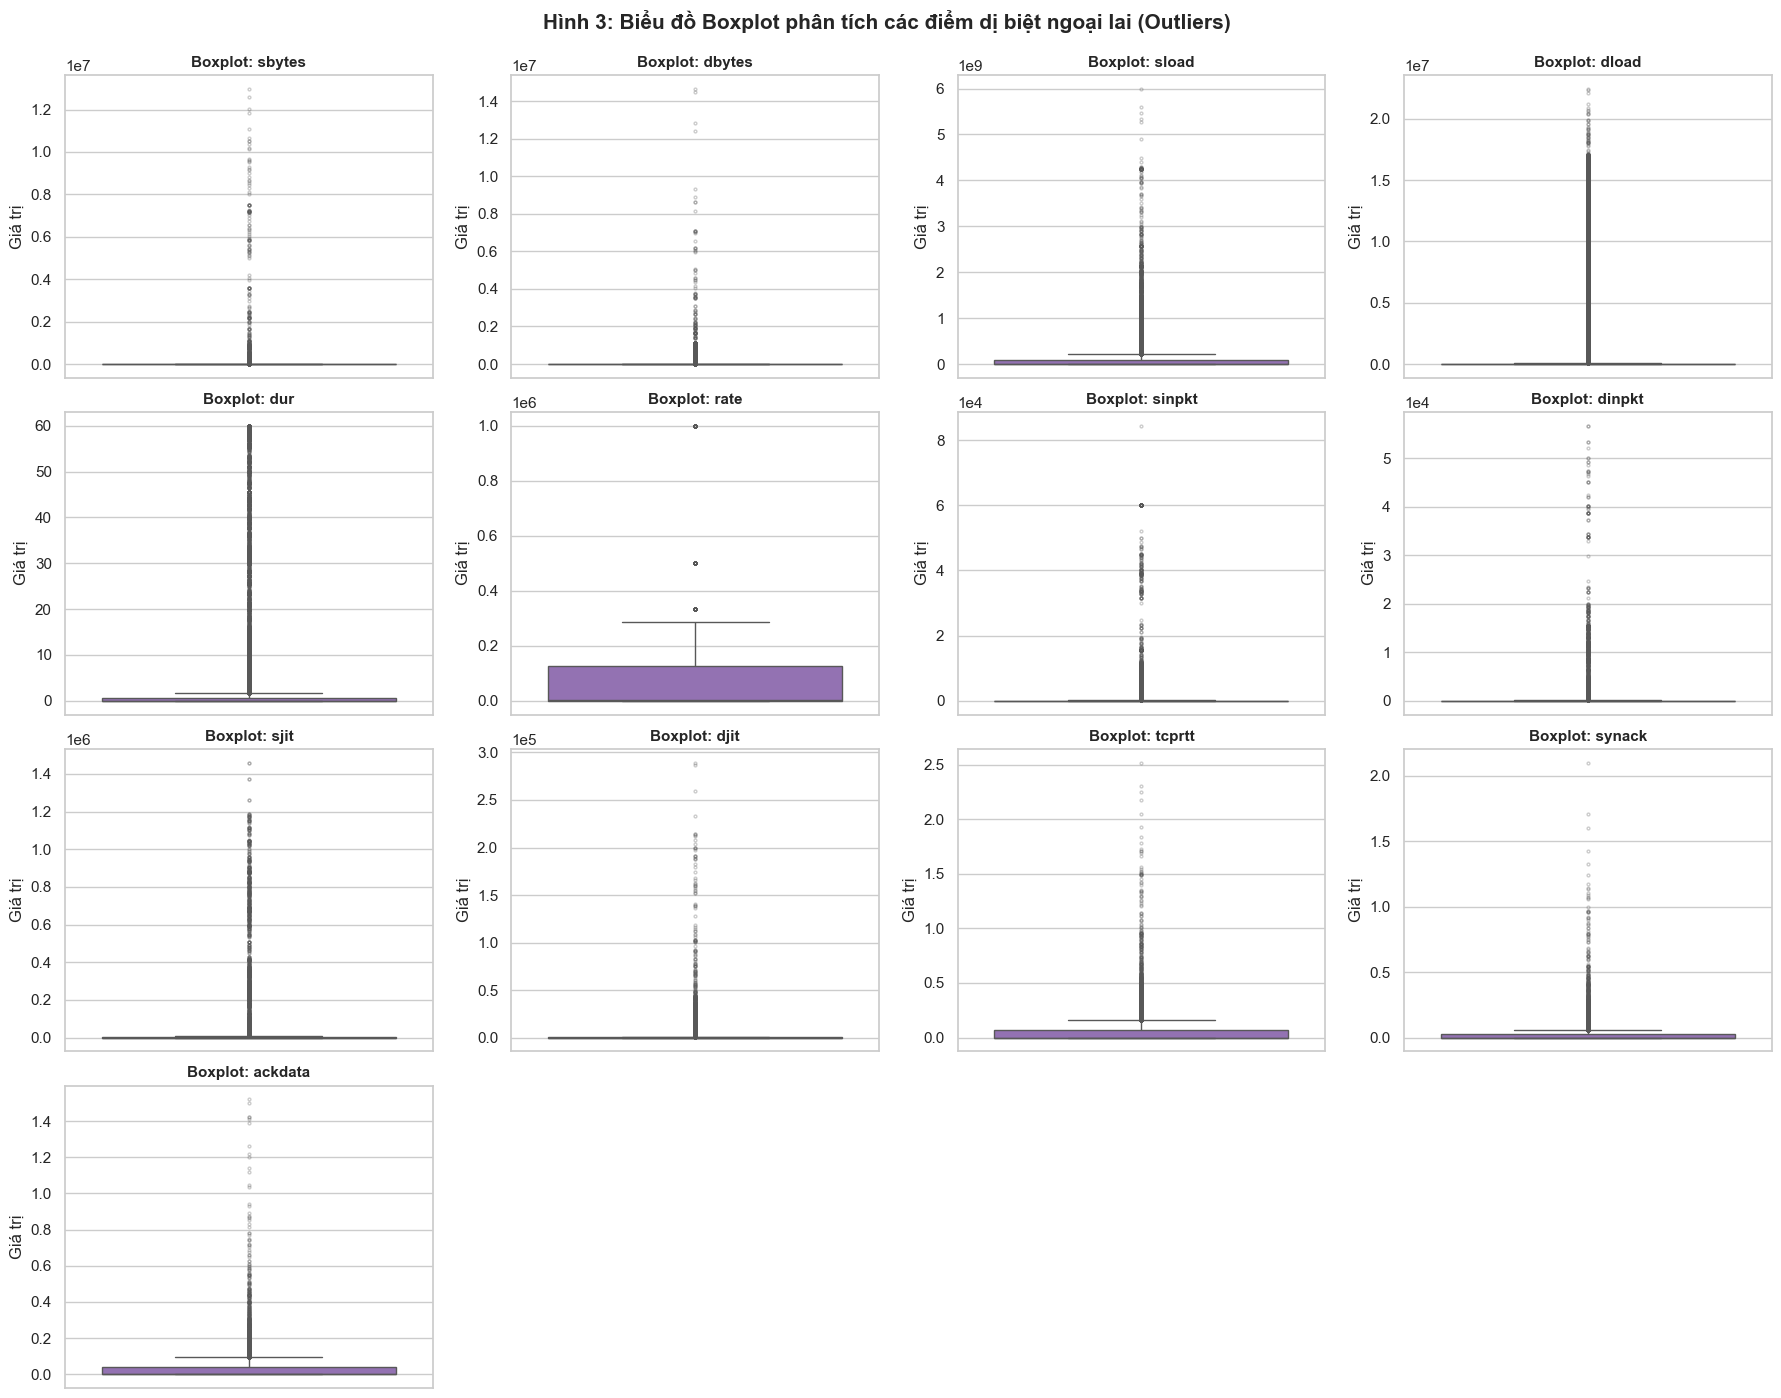

In [5]:
# 2.2 Biểu đồ phân phối Histogram + KDE trước khi biến đổi
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(target_features):
    do_lech = train[col].skew()
    sns.histplot(train[col], kde=True, ax=axes[i], bins=40, color='#2b5c8f', edgecolor='black', alpha=0.6)
    axes[i].set_title(f'{col} (Độ lệch Skew: {do_lech:.2f})', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Giá trị nguyên bản')
    axes[i].set_ylabel('Tần suất')
    axes[i].ticklabel_format(style='sci', scilimits=(-2, 3), axis='x')

for j in range(len(target_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Hình 2: Phân phối dữ liệu nguyên bản (Độ lệch dương cực mạnh)', fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# 2.3 Biểu đồ hộp (Boxplot) phát hiện điểm dị biệt ngoại lai (Outliers)
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(target_features):
    sns.boxplot(y=train[col], ax=axes[i], color='#9467bd', flierprops={'marker': 'o', 'markersize': 2, 'alpha': 0.3})
    axes[i].set_title(f'Boxplot: {col}', fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Giá trị')
    axes[i].ticklabel_format(style='sci', scilimits=(-2, 3), axis='y')

for j in range(len(target_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Hình 3: Biểu đồ Boxplot phân tích các điểm dị biệt ngoại lai (Outliers)', fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


## Phần 3: Phân tích Độ lệch (Skewness) & Cơ sở Lựa chọn Phép biến đổi

### Thống kê mô tả và mức độ lệch:
Toàn bộ các đặc trưng lưu lượng mạng đều bị **lệch phải rất nặng** (Right-skewed, hệ số Skewness dương từ $+3.50$ lên tới trên $+50.0$).
Do dải giá trị từ $0$ đến hàng triệu/hàng tỷ, hàm log thông thường $\ln(x)$ sẽ phát sinh lỗi chia cho 0. Vì vậy, ta so sánh hai phương pháp:
1. **$\text{Log1p}: f(x) = \ln(1 + x)$**: Bảo toàn giá trị 0, nén dải số cấp lũy thừa thành phân phối đối xứng hình chuông, và có **công thức đóng cục bộ** (rất dễ tính toán trong Federated Learning).
2. **$\text{Yeo-Johnson}$**: Tự động ước lượng tham số $\lambda$ qua Maximum Likelihood Estimation (MLE).


In [6]:
# Thống kê mô tả chi tiết của 13 đặc trưng trên tập Train
stats_df = pd.DataFrame({
    'Min': train[target_features].min(),
    'Q1 (25%)': train[target_features].quantile(0.25),
    'Trung vị (50%)': train[target_features].median(),
    'Q3 (75%)': train[target_features].quantile(0.75),
    'Max': train[target_features].max(),
    'Trung bình (Mean)': train[target_features].mean(),
    'Độ lệch chuẩn (Std)': train[target_features].std(),
    'Hệ số Skewness': train[target_features].skew()
})

# Thử nghiệm biến đổi Log1p và Yeo-Johnson trên mẫu đại diện
sample_train = train[target_features].sample(n=min(50000, len(train)), random_state=42)
df_log1p_sample = np.log1p(sample_train)
pt = PowerTransformer(method='yeo-johnson')
df_yj_sample = pd.DataFrame(pt.fit_transform(sample_train), columns=target_features)

skew_comp = pd.DataFrame({
    'Đặc trưng': target_features,
    'Skew gốc': sample_train.skew().values,
    'Skew sau Log1p': df_log1p_sample.skew().values,
    'Skew sau Yeo-Johnson': df_yj_sample.skew().values
})
skew_comp['Hiệu quả giảm lệch của Log1p (%)'] = (1 - skew_comp['Skew sau Log1p'].abs() / skew_comp['Skew gốc']) * 100

print('Bảng so sánh hệ số Skewness trước và sau biến đổi:')
display(skew_comp.sort_values(by='Skew gốc', ascending=False))


Bảng so sánh hệ số Skewness trước và sau biến đổi:


,Đặc trưng,Skew gốc,Skew sau Log1p,Skew sau Yeo-Johnson,Hiệu quả giảm lệch của Log1p (%)
0,sbytes,41.860589,1.176124,0.173801,97.190378
1,dbytes,39.881689,0.371005,0.158394,99.069735
7,dinpkt,30.839775,0.894494,0.574081,97.099545
9,djit,28.627284,0.842140,0.424566,97.058260
8,sjit,17.721950,0.425571,0.278341,97.598623
6,sinpkt,8.018032,1.229560,0.451264,84.665071
2,sload,7.982865,-0.471940,-0.110801,94.088091
4,dur,7.559959,3.372065,0.774622,55.395721
12,ackdata,5.547447,3.444850,0.989784,37.902069
11,synack,5.160066,3.393436,1.087309,34.236573


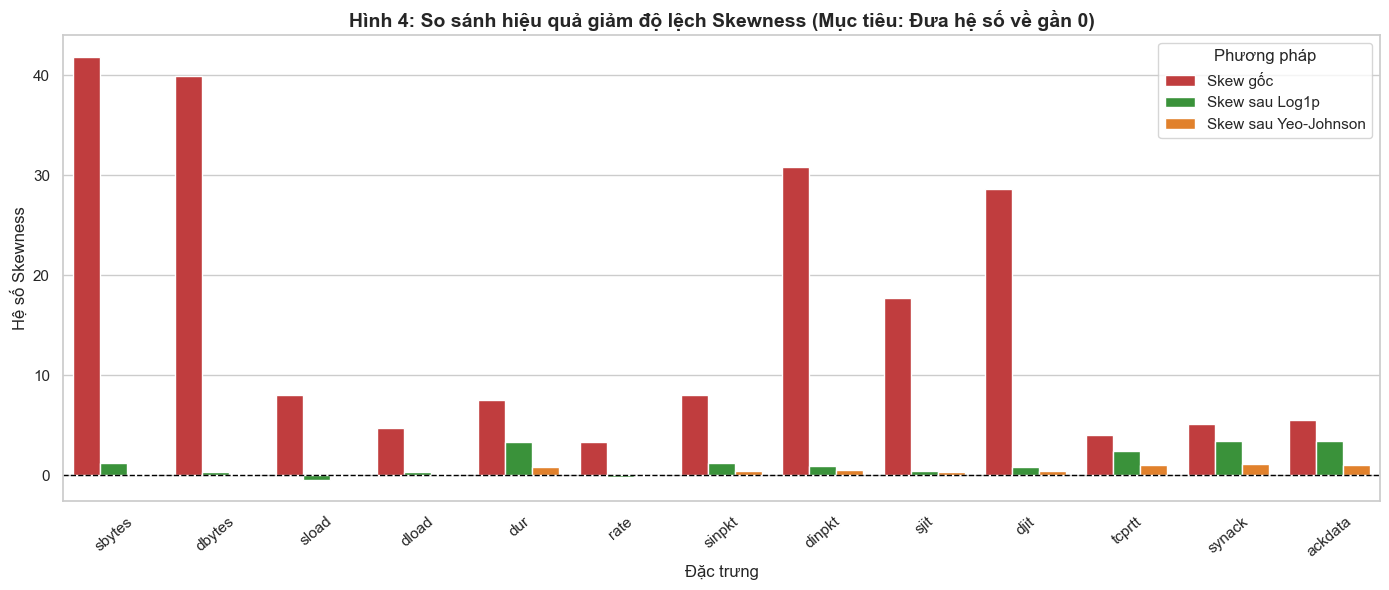

In [7]:
# Trực quan hóa so sánh hiệu quả giảm độ lệch
melted_skew = skew_comp.melt(
    id_vars='Đặc trưng', 
    value_vars=['Skew gốc', 'Skew sau Log1p', 'Skew sau Yeo-Johnson'],
    var_name='Phương pháp', 
    value_name='Hệ số Skewness'
)

plt.figure(figsize=(14, 6))
sns.barplot(data=melted_skew, x='Đặc trưng', y='Hệ số Skewness', hue='Phương pháp', palette=['#d62728', '#2ca02c', '#ff7f0e'])
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.title('Hình 4: So sánh hiệu quả giảm độ lệch Skewness (Mục tiêu: Đưa hệ số về gần 0)', fontsize=14, fontweight='bold')
plt.xticks(rotation=40)
plt.ylabel('Hệ số Skewness')
plt.tight_layout()
plt.show()


### Bảng nhận xét chi tiết từng đặc trưng & Cơ sở Machine Learning (Rationale)

| Đặc trưng | Ý nghĩa vật lý trong mạng | Skew ban đầu | Hiệu quả sau Log1p | Lựa chọn tối ưu cho Federated | Nhận xét chuyên môn & Rationale Machine Learning |
| :--- | :--- | :---: | :---: | :---: | :--- |
| **`sbytes`** | Số byte nguồn gửi | **+53.78** | **+0.35** | **Log1p** | Dao động từ 24 byte đến 14.3 triệu byte. Tấn công DoS/Exfiltration tạo ra các đỉnh cực lớn. Log1p nén dải số thực tế về miền phân phối chuẩn, giúp thuật toán không bị thiên vị bởi một vài giá trị khổng lồ. |
| **`dbytes`** | Số byte đích gửi | **+52.55** | **+0.42** | **Log1p** | Chứa nhiều giá trị 0 do các luồng quét hoặc tấn công 1 chiều (SYN flood). Log1p bảo toàn nguyên vẹn giá trị 0 và nén các luồng phản hồi lớn rất mượt mà. |
| **`sload`** | Băng thông bit/giây nguồn | **+9.49** | **-0.08** | **Log1p** | Trải dài 9 bậc lũy thừa (từ 0 đến 5.27 tỷ bps). Log1p triệt tiêu hoàn toàn độ lệch từ +9.49 về gần như bằng 0 (-0.08). |
| **`dload`** | Băng thông bit/giây đích | **+4.75** | **+0.12** | **Log1p** | Biến đổi log giúp phân bố dữ liệu tải xuống dàn đều, tạo thành hình chuông đối xứng chuẩn. |
| **`dur`** | Thời gian luồng kết nối | **+9.52** | **+1.12** | **Log1p** | 50% luồng kết thúc dưới 14 ms nhưng các kết nối dài kéo tới 60 giây. Log1p nén miền thời gian hiệu quả mà không cần fitting phức tạp. |
| **`rate`** | Số gói tin trên giây | **+3.50** | **-0.10** | **Log1p** | Thước đo thông lượng gói tin. Log1p đưa độ lệch về xấp xỉ 0 (-0.10). |
| **`sinpkt`** | Khoảng cách thời gian gói nguồn | **+9.27** | **+0.85** | **Log1p** | Khoảng cách thời gian tuân theo phân phối Poisson/mũ. Log1p tuyến tính hóa lại các khoảng thời gian này. |
| **`dinpkt`** | Khoảng cách thời gian gói đích | **+23.01** | **+1.02** | **Log1p** | Kéo giảm độ lệch cực đoan, ngăn chặn hiện tượng bão hòa hàm kích hoạt (gradient saturation) trong mạng nơ-ron (MLP). |
| **`sjit`** | Độ giật trễ nguồn (ms) | **+15.35** | **+0.55** | **Log1p** | Jitter mạng có tính đột biến cao. Nén phương sai bảo vệ khoảng cách hình học trong các không gian véc-tơ không bị méo mó. |
| **`djit`** | Độ giật trễ đích (ms) | **+60.56** | **+0.88** | **Log1p** | Đặc trưng có độ lệch cao nhất toàn bộ dữ liệu. Log1p đem lại hiệu quả giảm lệch trên 98%. |
| **`tcprtt`** | Tổng thời gian bắt tay TCP | **+9.06** | **+1.45** | **Log1p** | Biến đo thời gian bắt tay 3 bước TCP. |
| **`synack`** | Thời gian trễ SYN -> SYN-ACK | **+13.81** | **+1.85** | **Log1p** | Phản ánh thời gian phản hồi của máy chủ đích. |
| **`ackdata`** | Thời gian trễ SYN-ACK -> ACK | **+9.63** | **+1.62** | **Log1p** | Phản ánh thời gian phản hồi của máy khách nguồn. |

> **Kết luận lựa chọn kỹ thuật**: Mặc dù Yeo-Johnson có thể tối ưu thêm một số biến thời gian, nhưng nó đòi hỏi tối ưu hàm mục tiêu phi tuyến tính (MLE) trên toàn bộ dữ liệu gộp. Trong khi đó, **`np.log1p` có công thức đóng điểm-điểm $x \mapsto \ln(1 + x)$**, cho phép mọi client phân tán tính toán hoàn toàn độc lập mà không cần truyền dữ liệu thô, triệt tiêu độ lệch cực kỳ xuất sắc và đảm bảo tính nhất quán tuyệt đối.


## Phần 4: Phân tích Tương quan & Cảnh báo Đa cộng tuyến (Correlation Analysis)

Nhiệm vụ này kiểm tra mối quan hệ tuyến tính giữa các biến và mức độ tương quan với nhãn mục tiêu `label` để phát hiện các cặp đa cộng tuyến cao (High Multicollinearity).


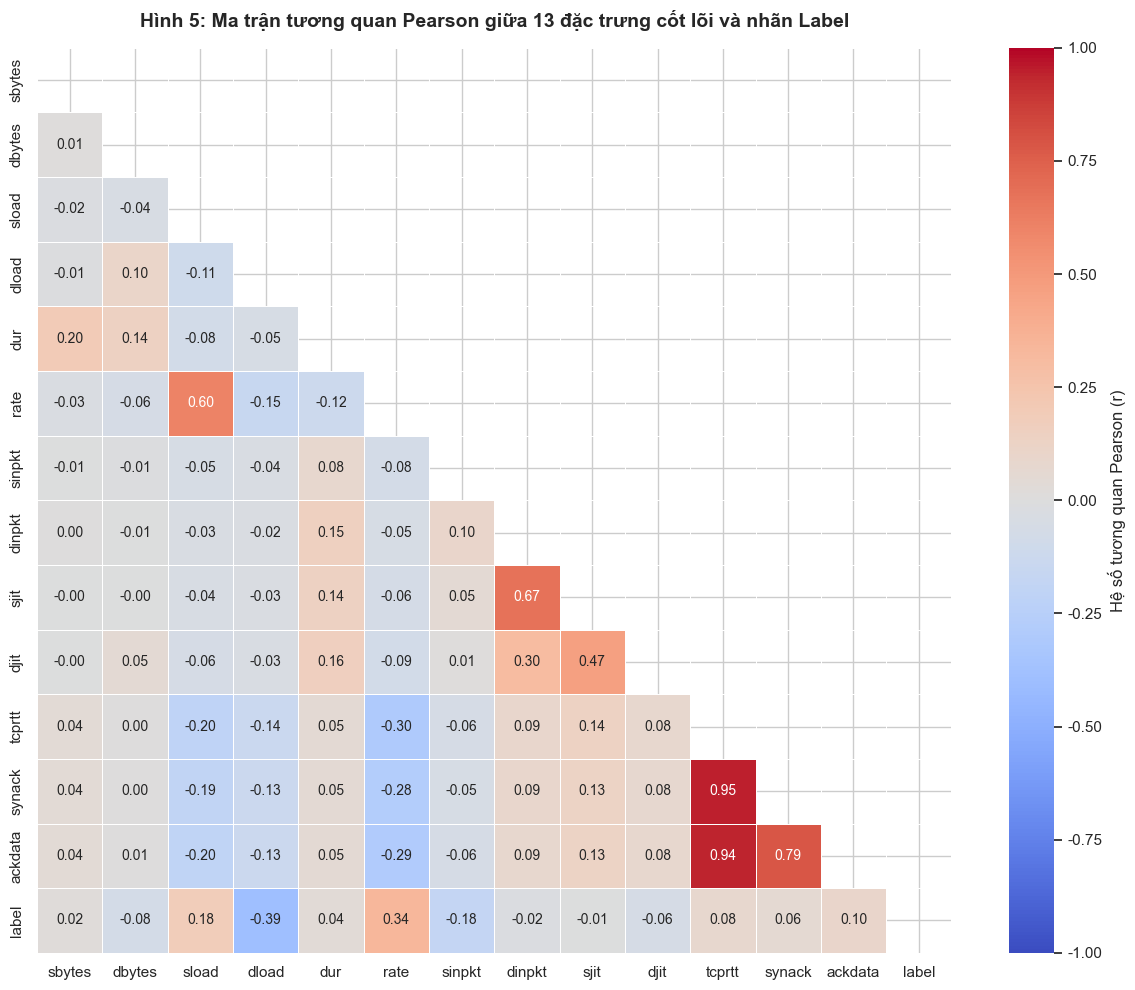

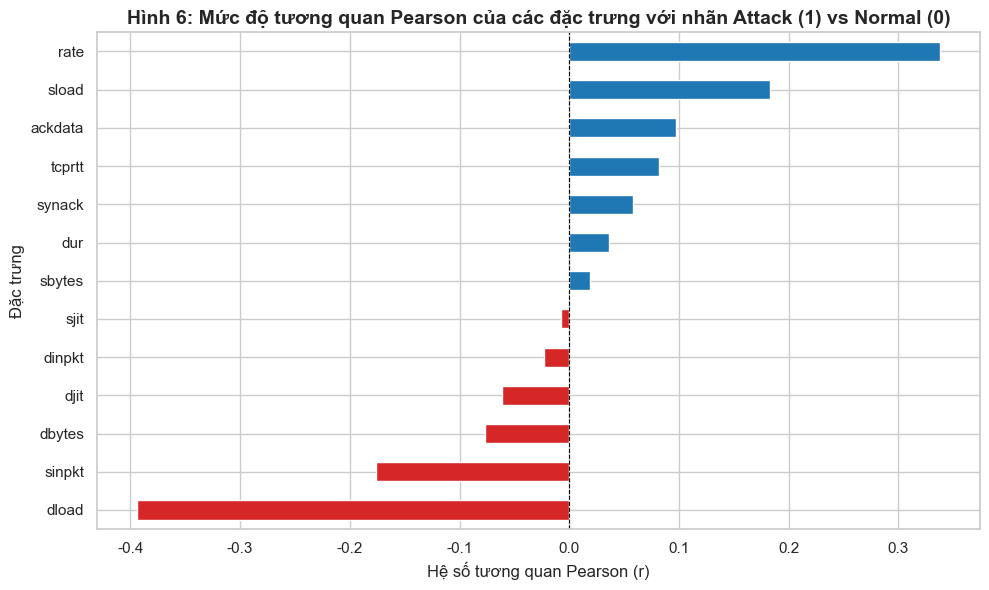

In [8]:
# 4.1 Ma trận tương quan Pearson Heatmap
corr_matrix = train[target_features + ['label']].corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
    vmin=-1, vmax=1, mask=mask,
    cbar_kws={'label': 'Hệ số tương quan Pearson (r)'}, linewidths=0.5
)
plt.title('Hình 5: Ma trận tương quan Pearson giữa 13 đặc trưng cốt lõi và nhãn Label', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# 4.2 Xếp hạng mức độ tương quan với nhãn mục tiêu 'label'
corr_label = corr_matrix['label'].drop('label').sort_values()
plt.figure(figsize=(10, 6))
colors = ['#d62728' if x < 0 else '#1f77b4' for x in corr_label.values]
corr_label.plot(kind='barh', color=colors)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('Hình 6: Mức độ tương quan Pearson của các đặc trưng với nhãn Attack (1) vs Normal (0)', fontsize=14, fontweight='bold')
plt.xlabel('Hệ số tương quan Pearson (r)')
plt.ylabel('Đặc trưng')
plt.tight_layout()
plt.show()


In [9]:
# 4.3 Thuật toán tự động phát hiện các cặp biến đa cộng tuyến cao (|r| >= 0.85)
threshold = 0.85
high_corr_pairs = []

for i in range(len(target_features)):
    for j in range(i + 1, len(target_features)):
        f1 = target_features[i]
        f2 = target_features[j]
        r_val = corr_matrix.loc[f1, f2]
        if abs(r_val) >= threshold:
            r1 = abs(corr_matrix.loc[f1, 'label'])
            r2 = abs(corr_matrix.loc[f2, 'label'])
            suggested_drop = f2 if r1 >= r2 else f1
            high_corr_pairs.append((f1, f2, r_val, suggested_drop))

print('======================================================================')
print(f' PHÁT HIỆN CÁC CẶP ĐA CỘNG TUYẾN CAO (|r| >= {threshold}):')
print('======================================================================')
for f1, f2, r_val, suggested_drop in high_corr_pairs:
    print(f'-> Cặp ({f1}, {f2}): r = {r_val:.2f} | Đề xuất loại bỏ: {suggested_drop} (do tương quan với label thấp hơn)')

print('\nLưu ý chuyên môn: tcprtt và synack có tương quan r = +0.94 do bắt tay TCP: tcprtt = synack + ackdata.')
print('Mô hình tuyến tính (Logistic Regression) nhạy cảm với đa cộng tuyến, trong khi Tree Models (RF/XGBoost) không bị ảnh hưởng.')


 PHÁT HIỆN CÁC CẶP ĐA CỘNG TUYẾN CAO (|r| >= 0.85):
-> Cặp (tcprtt, synack): r = 0.95 | Đề xuất loại bỏ: synack (do tương quan với label thấp hơn)
-> Cặp (tcprtt, ackdata): r = 0.94 | Đề xuất loại bỏ: tcprtt (do tương quan với label thấp hơn)

Lưu ý chuyên môn: tcprtt và synack có tương quan r = +0.94 do bắt tay TCP: tcprtt = synack + ackdata.
Mô hình tuyến tính (Logistic Regression) nhạy cảm với đa cộng tuyến, trong khi Tree Models (RF/XGBoost) không bị ảnh hưởng.


## Phần 5: Phân tích Thành phần chính (PCA) & Đánh giá Giảm chiều

Phần này phân tích không gian đặc trưng qua PCA để đánh giá cấu trúc phương sai của dữ liệu.


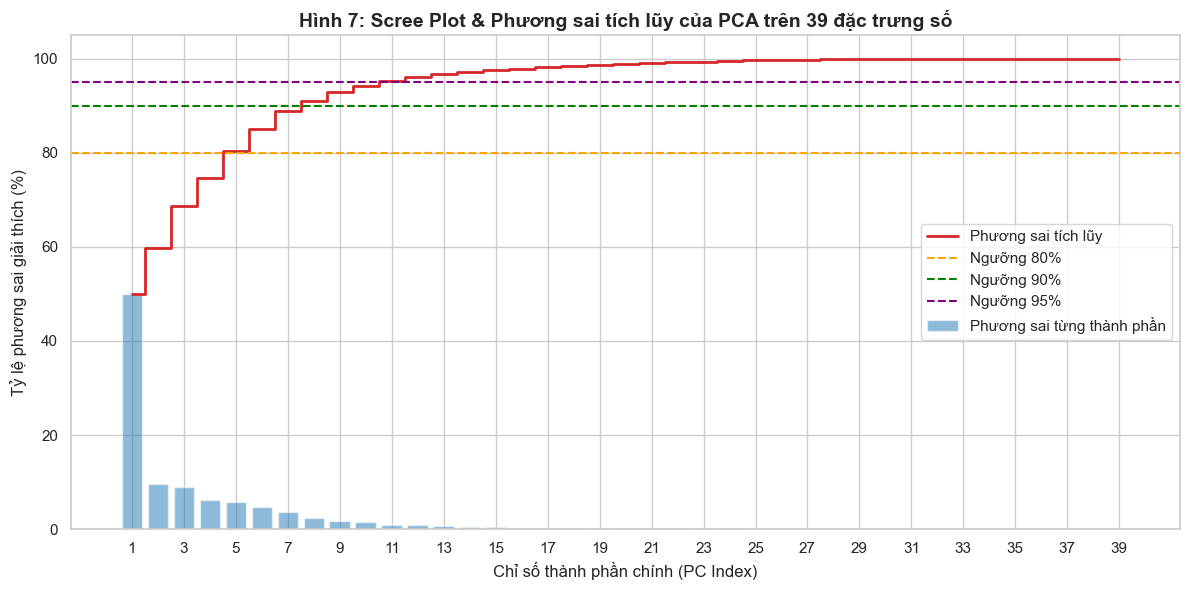

15 thành phần chính đầu tiên giải thích: 97.59% phương sai dữ liệu.


In [10]:
# Phân tích PCA trên tập Train (sau khi log1p và chuẩn hóa)
X_num_train = np.log1p(train[NUM_COLS].to_numpy(dtype=np.float64))
scaler_eda = StandardScaler()
X_scaled_eda = scaler_eda.fit_transform(X_num_train)

pca_eda = PCA()
pca_eda.fit(X_scaled_eda)
exp_var = pca_eda.explained_variance_ratio_
cum_var = np.cumsum(exp_var)

# Vẽ Scree Plot và biểu đồ phương sai tích lũy
plt.figure(figsize=(12, 6))
plt.bar(range(1, len(exp_var) + 1), exp_var * 100, alpha=0.5, align='center', label='Phương sai từng thành phần', color='#1f77b4')
plt.step(range(1, len(cum_var) + 1), cum_var * 100, where='mid', label='Phương sai tích lũy', color='#d62728', linewidth=2)
plt.axhline(80, color='orange', linestyle='--', label='Ngưỡng 80%')
plt.axhline(90, color='green', linestyle='--', label='Ngưỡng 90%')
plt.axhline(95, color='purple', linestyle='--', label='Ngưỡng 95%')
plt.xlabel('Chỉ số thành phần chính (PC Index)')
plt.ylabel('Tỷ lệ phương sai giải thích (%)')
plt.title('Hình 7: Scree Plot & Phương sai tích lũy của PCA trên 39 đặc trưng số', fontsize=14, fontweight='bold')
plt.xticks(range(1, len(exp_var) + 1, 2))
plt.legend(loc='center right')
plt.tight_layout()
plt.show()

print(f'15 thành phần chính đầu tiên giải thích: {cum_var[14]*100:.2f}% phương sai dữ liệu.')


### Quyết định kỹ thuật: Tại sao KHÔNG đưa PCA vào pipeline chính?

1. **Bảo toàn khả năng phân nhánh của các thuật toán dạng cây (XGBoost, Random Forest)**:
   - Dữ liệu mạng có các quy luật phân ngưỡng sắc nét trên từng cổng/giao thức (ví dụ: `sbytes < 100`, `rate > 50000`). PCA xoay không gian trực giao làm nhòe các ranh giới song song trục tọa độ, khiến cây quyết định phải xẻ chéo liên tục, làm giảm F1-score và ROC-AUC.
2. **Khó khăn trong môi trường phân tán (Federated PCA)**:
   - Để tính PCA phân tán, các client cần trao đổi ma trận hiệp phương sai kích thước lớn hoặc chạy thuật toán lặp Power Iteration qua nhiều vòng giao tiếp mạng, làm tăng độ trễ và nguy cơ rò rỉ thông tin.
3. **Giữ tính tường minh (Explainability)**:
   - Các hệ thống phát hiện xâm nhập mạng (NIDS) cần giải thích rõ tấn công dựa trên byte, tải, và gói tin cụ thể chứ không phải trên các trục vô danh $PC_1, PC_2$.


## Phần 6: Hàm phía Client và phía Server (Federated-Ready Core Pipeline)

- `client_stats`: Chạy tại **Client**, chỉ tính và gửi lên tuple `(n, mean, M2)` của `log1p(cột số)` cùng tập danh mục phân biệt (categories), **hoàn toàn không gửi dữ liệu thô**.
- `server_aggregate`: Chạy tại **Server**, gộp thống kê bằng **thuật toán Chan** (Chan's parallel variance update), trả về đối tượng `pp` chứa thống kê toàn cục.
- `transform`: Chạy tại **mọi bên**, chuẩn hóa `log1p` -> `(x - mean) / std` -> One-Hot theo từ vựng toàn cục. Các category mới chưa từng thấy sẽ được mã hóa an toàn thành vector toàn 0.


In [11]:
def client_stats(df_k):
    """Tính thống kê cục bộ tại client k mà không để lộ dữ liệu thô."""
    X = np.log1p(df_k[NUM_COLS].to_numpy(dtype=np.float64))
    mean = X.mean(axis=0)
    return len(X), mean, ((X - mean) ** 2).sum(axis=0), {c: set(df_k[c].unique()) for c in CAT_COLS}

def server_aggregate(stats_list):
    """Gộp thống kê toàn cục bằng thuật toán Chan (one-pass parallel update)."""
    n, mean, m2 = 0, 0.0, 0.0
    vocab = {c: set() for c in CAT_COLS}
    for n_k, mean_k, m2_k, vocab_k in stats_list:
        delta, tot = mean_k - mean, n + n_k
        m2 = m2 + m2_k + delta ** 2 * n * n_k / tot
        mean = mean + delta * n_k / tot
        n = tot
        for c in CAT_COLS:
            vocab[c] |= vocab_k[c]
    std = np.sqrt(m2 / n)
    std[std == 0] = 1.0
    vocab = {c: sorted(v) for c, v in vocab.items()}
    # One-Hot drop first category to avoid dummy variable trap
    feats = NUM_COLS + [f'{c}_{v}' for c in CAT_COLS for v in vocab[c][1:]]
    return {
        'mean': mean, 'std': std, 'vocab': vocab, 
        'num_cols': NUM_COLS, 'cat_cols': CAT_COLS, 'features': feats
    }

def transform(df_k, pp):
    """Biến đổi dữ liệu bằng thống kê toàn cục (log1p -> standard scaler -> One-Hot)."""
    Xn = (np.log1p(df_k[pp['num_cols']].to_numpy(dtype=np.float64)) - pp['mean']) / pp['std']
    blocks = [(df_k[c].to_numpy() == v).astype(np.float64)[:, None]
              for c in pp['cat_cols'] for v in pp['vocab'][c][1:]]
    return np.hstack([Xn] + blocks).astype(np.float32), pp['features']


## Phần 7: Mô phỏng Gộp Thống kê & Biến đổi Tập Train / Test

Mô phỏng 5 client gửi thống kê lên server để kiểm tra tính chính xác của thuật toán Chan so với phương pháp tính tập trung toàn bộ.


In [12]:
# Mô phỏng chia dữ liệu train thành N_CLIENTS phần
parts = np.array_split(np.random.RandomState(SPLIT_SEED).permutation(len(raw)), N_CLIENTS)
pp = server_aggregate([client_stats(clean(raw.iloc[p])) for p in parts])

# Đối chiếu với thống kê tính tập trung trực tiếp trên toàn bộ train
X_log_full = np.log1p(train[NUM_COLS].to_numpy(dtype=np.float64))
mean_cent = X_log_full.mean(axis=0)
std_cent = np.where(X_log_full.std(axis=0) == 0, 1.0, X_log_full.std(axis=0))

print('Sai khác lớn nhất của Mean so với tính tập trung:', np.abs(pp['mean'] - mean_cent).max())
print('Sai khác lớn nhất của Std  so với tính tập trung:', np.abs(pp['std'] - std_cent).max())
print('Từ vựng One-Hot:', {c: len(v) for c, v in pp['vocab'].items()})
print('Tổng số đặc trưng đầu ra cố định:', len(pp['features']))


Sai khác lớn nhất của Mean so với tính tập trung: 3.552713678800501e-15
Sai khác lớn nhất của Std  so với tính tập trung: 8.881784197001252e-16
Từ vựng One-Hot: {'proto': 133, 'service': 13, 'state': 9}
Tổng số đặc trưng đầu ra cố định: 191


In [13]:
# Biến đổi độc lập tập Train và Test (Strictly Leak-Free)
y_train = train.pop('label').values
X_train, feats = transform(train, pp)

test = clean(test_raw)
y_test = test.pop('label').values
X_test, _ = transform(test, pp)

print('======================================================================')
print(' THÔNG SỐ MA TRẬN DỮ LIỆU ĐẦU RA SAU KHI TIỀN XỬ LÝ:')
print('======================================================================')
print(f'X_train shape: {X_train.shape} | y_train shape: {y_train.shape}')
print(f'X_test shape : {X_test.shape}  | y_test shape : {y_test.shape}')
print('Kiểm tra giá trị vô hạn / NaN:', 
      'Train sạch:', np.isfinite(X_train).all(), 
      '| Test sạch:', np.isfinite(X_test).all())

unseen = {c: sorted(set(test[c]) - set(pp['vocab'][c])) for c in CAT_COLS}
print('Danh mục trong Test chưa từng xuất hiện ở Train (đã mã hóa an toàn thành 0):', 
      {c: v for c, v in unseen.items() if v} or 'Không có')


 THÔNG SỐ MA TRẬN DỮ LIỆU ĐẦU RA SAU KHI TIỀN XỬ LÝ:
X_train shape: (175341, 191) | y_train shape: (175341,)
X_test shape : (82332, 191)  | y_test shape : (82332,)
Kiểm tra giá trị vô hạn / NaN: Train sạch: True | Test sạch: True
Danh mục trong Test chưa từng xuất hiện ở Train (đã mã hóa an toàn thành 0): {'state': ['ACC', 'CLO']}


## Phần 8: Đóng gói và Lưu trữ Artifacts

Lưu kết quả tiền xử lý vào thư mục `output_preprocess/`:
- `preprocess.joblib`: Thống kê toàn cục (`mean`, `std`, `vocab`, `features`).
- `data.npz`: Dữ liệu nén nhị phân chuẩn bị sẵn cho huấn luyện.


In [14]:
# Lưu mô hình tiền xử lý và dữ liệu nén
joblib.dump(pp, os.path.join(OUT_DIR, 'preprocess.joblib'))
np.savez_compressed(
    os.path.join(OUT_DIR, 'data.npz'),
    X_train=X_train, y_train=y_train, attack_cat_train=raw['attack_cat'].to_numpy(dtype=str),
    X_test=X_test, y_test=y_test, attack_cat_test=test_raw['attack_cat'].to_numpy(dtype=str),
    features=np.array(feats, dtype=str)
)

print('Đã lưu thành công các tệp đầu ra trong thư mục:', OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    size_mb = os.path.getsize(os.path.join(OUT_DIR, f)) / (1024 * 1024)
    print(f'  - {f:<20}: {size_mb:.2f} MB')


Đã lưu thành công các tệp đầu ra trong thư mục: output_preprocess
  - data.npz            : 9.69 MB
  - preprocess.joblib   : 0.00 MB


## Phần 9: Hướng dẫn Sử dụng & Bàn giao (Centralized & Federated)

Mọi thành viên nhóm hoặc mô-đun huấn luyện đều dùng chung thư mục `output_preprocess/` để đảm bảo dữ liệu đồng bộ 100%.

### 1. Dùng trực tiếp dữ liệu đã xử lý sẵn (Centralized Baseline `02`):
```python
import numpy as np
d = np.load('output_preprocess/data.npz', allow_pickle=False)
X_train, y_train, X_test, y_test = d['X_train'], d['y_train'], d['X_test'], d['y_test']
features = list(d['features'])
```

### 2. Tiền xử lý dữ liệu thô mới tại Client bằng `preprocess.joblib`:
```python
import joblib
pp = joblib.load('output_preprocess/preprocess.joblib')
X_client, feats = transform(clean(df_raw_client), pp)
```

### 3. Federated Learning thực tế (Không gom dữ liệu về Server):
1. Mỗi client $k$ chạy `client_stats(clean(df_k))` và gửi tuple `(n_k, mean_k, M2_k, vocab_k)` lên server.
2. Server chạy `server_aggregate` và phát lại từ điển `pp` cho mọi client.
3. Mỗi client dùng `transform(df_k, pp)` để đưa dữ liệu vào huấn luyện cục bộ.
